In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

warnings.filterwarnings("ignore")

In [2]:
#Load Model Tables

df = pd.read_csv("../outputs/model_table.csv")
df.shape

(25000, 20)

In [3]:
df["registration_date"] = pd.to_datetime(df["registration_date"], errors="coerce")
df["visit_date"] = pd.to_datetime(df["visit_date"], errors="coerce")
df["billing_date"] = pd.to_datetime(df["billing_date"], errors="coerce")
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   patient_id            25000 non-null  int64         
 1   age                   25000 non-null  int64         
 2   gender                25000 non-null  str           
 3   city                  25000 non-null  str           
 4   insurance_provider    25000 non-null  str           
 5   chronic_flag          25000 non-null  int64         
 6   registration_date     25000 non-null  datetime64[us]
 7   visit_id              25000 non-null  int64         
 8   visit_date            25000 non-null  datetime64[us]
 9   department            25000 non-null  str           
 10  visit_type            25000 non-null  str           
 11  length_of_stay_hours  25000 non-null  float64       
 12  risk_score            25000 non-null  str           
 13  doctor_id             25000

In [4]:
df.describe(include="all").T 

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
patient_id,25000.0,NaN,NaN,NaN,2502.20312,1.0,1263.0,2503.0,3755.0,5000.0,1443.378814
age,25000.0,NaN,NaN,NaN,44.89464,1.0,22.0,45.0,67.0,90.0,25.858097
gender,25000,2,M,12732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,25000,6,Bangalore,4328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
insurance_provider,25000,4,HealthPlus,6499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chronic_flag,25000.0,NaN,NaN,NaN,0.49948,0.0,0.0,0.0,1.0,1.0,0.50001
registration_date,25000,NaN,NaN,NaN,2025-07-20 16:04:30.720000,2025-01-20 00:00:00,2025-04-19 00:00:00,2025-07-18 00:00:00,2025-10-21 00:00:00,2026-01-19 00:00:00,NaN
visit_id,25000.0,NaN,NaN,NaN,12500.5,1.0,6250.75,12500.5,18750.25,25000.0,7217.022701
visit_date,25000,NaN,NaN,NaN,2025-10-20 07:55:39.648000,2025-01-21 00:00:00,2025-09-01 00:00:00,2025-11-12 00:00:00,2025-12-27 00:00:00,2026-01-20 00:00:00,NaN
department,25000,6,General,5757,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
#distribution analysis

#Missing value analysis


In [6]:
#overall null check

df.isnull().sum().sort_values(ascending=False)

payment_days            9532
approved_amount         6156
patient_id                 0
age                        0
city                       0
gender                     0
insurance_provider         0
chronic_flag               0
visit_date                 0
department                 0
registration_date          0
visit_id                   0
length_of_stay_hours       0
visit_type                 0
risk_score                 0
doctor_id                  0
billed_amount              0
bill_id                    0
claim_status               0
billing_date               0
dtype: int64

In [7]:
df[["approved_amount", "payment_days", "length_of_stay_hours"]].isnull().sum()

approved_amount         6156
payment_days            9532
length_of_stay_hours       0
dtype: int64

In [8]:
#check A - Paid claims should always have an approved amount


df[
    (df["claim_status"] == "Paid") &
    (df["approved_amount"].isna())
].shape

(0, 20)

In [9]:
#check-B payment days missing breakdown by claim status
df[df["payment_days"].isna()]["claim_status"].value_counts()

claim_status
Rejected    5266
Pending     4266
Name: count, dtype: int64

In [10]:
#Check - c LOS should never be negative
(df["length_of_stay_hours"]<0).sum()

np.int64(0)

In [11]:
#categorical coloumn report

print("======Department======")
print(df["department"].value_counts())
print("\n======Visit Type======")
print(df["visit_type"].value_counts())
print("\n======Insurance provider======")
print(df["insurance_provider"].value_counts())
print("\n======City======")
print(df["city"].value_counts())


======Department======
department
General        5757
Orthopedics    4474
Cardiology     4071
ER             3896
ICU            3415
Neurology      3387
Name: count, dtype: int64

======Visit Type======
visit_type
OPD    14635
ER      5778
ICU     4587
Name: count, dtype: int64

======Insurance provider======
insurance_provider
HealthPlus    6499
CareOne       6326
SecureLife    6197
MediCareX     5978
Name: count, dtype: int64

======City======
city
Bangalore    4328
Mumbai       4267
Pune         4230
Delhi        4170
Hyderabad    4129
Chennai      3876
Name: count, dtype: int64


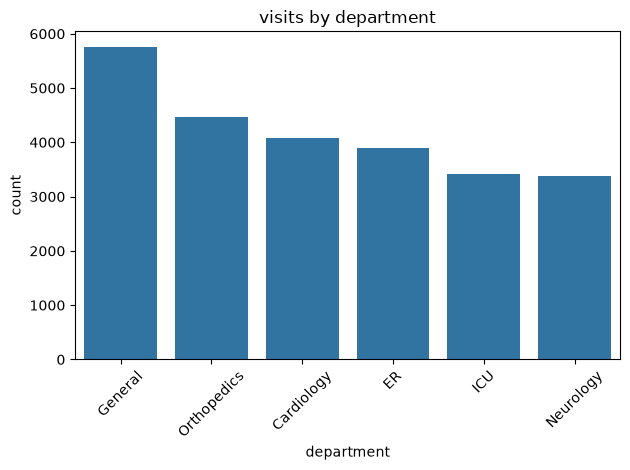

In [12]:
# Barchart showing visits by department
sns.countplot(data=df, x="department", order=df["department"].value_counts().index)
plt.xticks(rotation=45)
plt.title("visits by department")
plt.tight_layout()
plt.show()

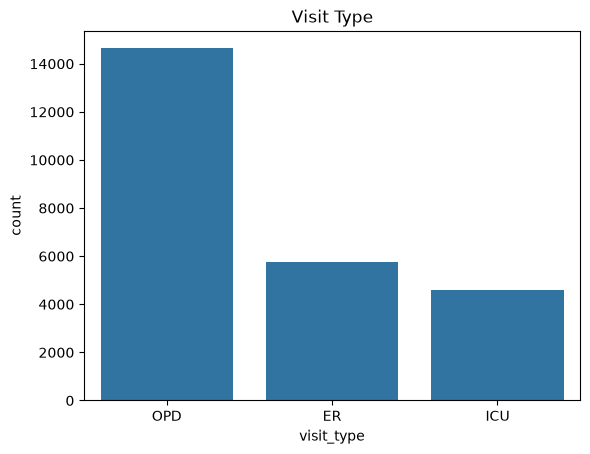

In [13]:
#Visits by type
sns.countplot(data=df, x = "visit_type", order=df["visit_type"].value_counts().index)
plt.title("Visit Type")
plt.show()

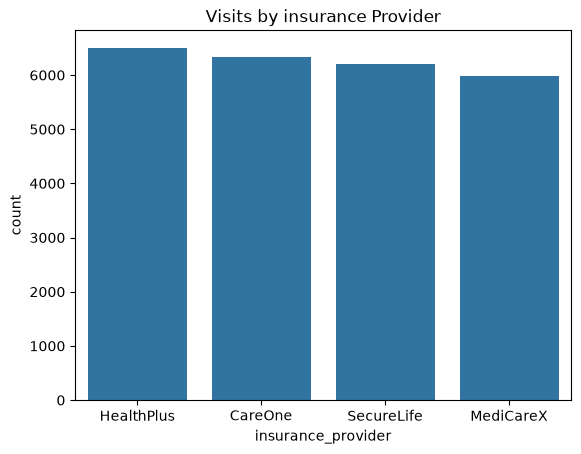

In [14]:
sns.countplot(data=df, x = "insurance_provider", order=df["insurance_provider"].value_counts().index)
plt.title("Visits by insurance Provider")
plt.show()

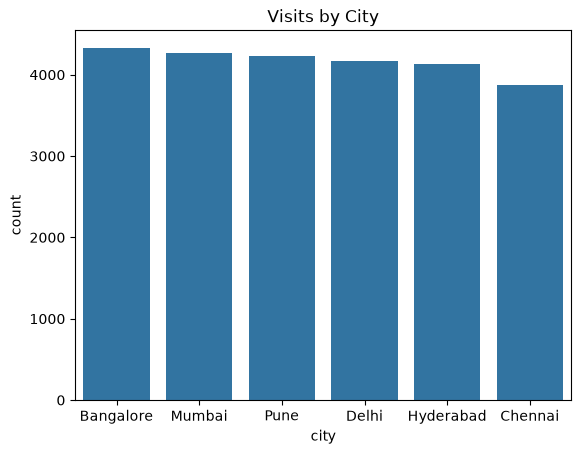

In [15]:
sns.countplot(data=df, x = "city", order=df["city"].value_counts().index)
plt.title("Visits by City")
plt.show()

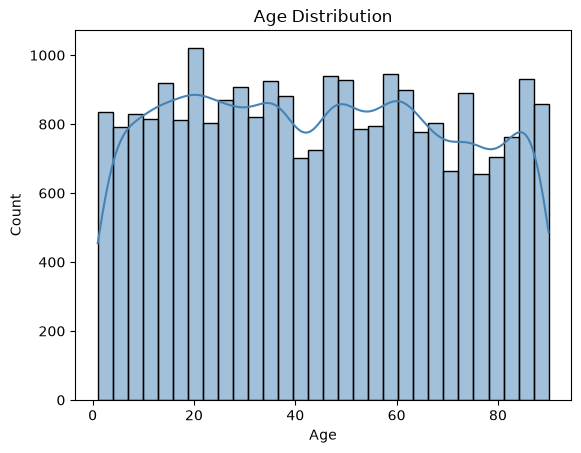

count    25000.00
mean        44.89
std         25.86
min          1.00
25%         22.00
50%         45.00
75%         67.00
max         90.00
Name: age, dtype: float64


In [16]:
#Age distribution
sns.histplot(df["age"], bins=30, kde=True, color="steelblue")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()
print(df["age"].describe().round(2))

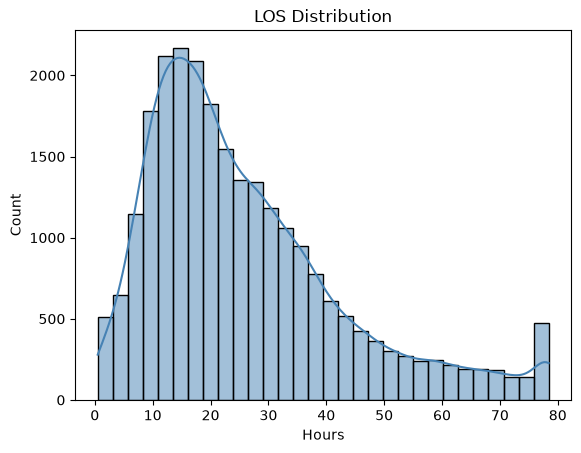

count    25000.00
mean        26.03
std         17.15
min          0.50
25%         13.54
50%         21.61
75%         34.22
max         78.42
Name: length_of_stay_hours, dtype: float64


In [17]:
#length of stay distribution
sns.histplot(df["length_of_stay_hours"], bins=30, kde=True, color="steelblue")
plt.title("LOS Distribution")
plt.xlabel("Hours")
plt.show()
print(df["length_of_stay_hours"].describe().round(2))

In [18]:
IQR = 27.31 - 9.96
print(IQR)

17.349999999999998


In [19]:
#upper fence
#outlier(value beyond and considered an outlier)
#jhons variable = 1.5(universal multiplier)
upper_fence = 27.31 + (1.5*17.35)
print(upper_fence)

53.335


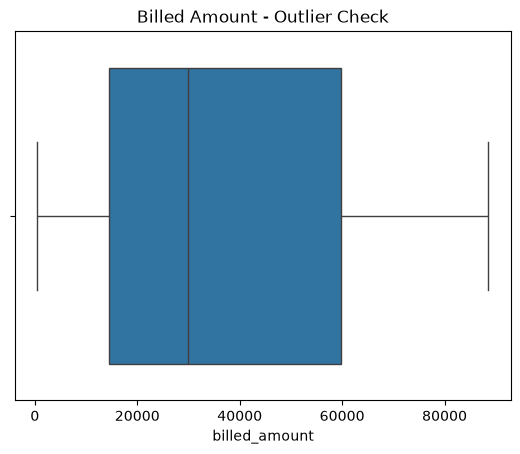

In [20]:
#outlier detection

sns.boxplot(x=df["billed_amount"])
plt.title("Billed Amount - Outlier Check")
plt.show()

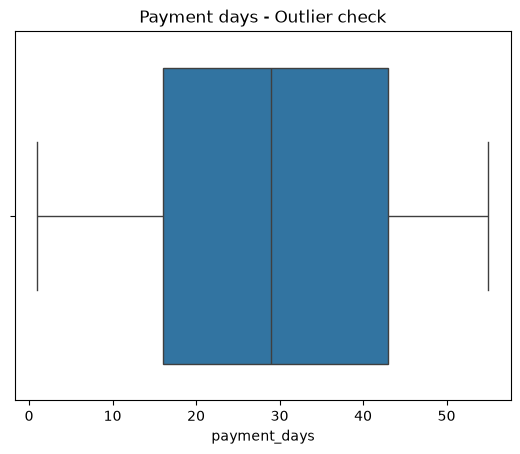

In [21]:
sns.boxplot(x=df["payment_days"])
plt.title("Payment days - Outlier check")
plt.show()

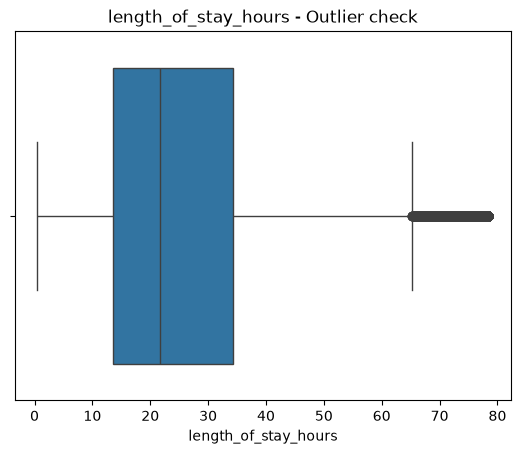

In [22]:
sns.boxplot(x=df["length_of_stay_hours"])
plt.title("length_of_stay_hours - Outlier check")
plt.show()

In [23]:
for col in ["length_of_stay_hours", "billed_amount", "payment_days"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3-Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col]<lower) | (df[col]>upper)).sum()
    print(f"{col}")
    print(f"Q1 = {Q1:.1} | Q3 = {Q3:.1f} | IQR = {IQR:.1f}" )
    print(f"Lower bound = {lower:.1f} | Upper bound = {upper:.1f}")
    print(f"Outliers = {n_out} rows")
    print()

length_of_stay_hours
Q1 = 1e+01 | Q3 = 34.2 | IQR = 20.7
Lower bound = -17.5 | Upper bound = 65.2
Outliers = 1136 rows

billed_amount
Q1 = 1e+04 | Q3 = 59710.5 | IQR = 45141.8
Lower bound = -53144.0 | Upper bound = 127423.3
Outliers = 0 rows

payment_days
Q1 = 2e+01 | Q3 = 43.0 | IQR = 27.0
Lower bound = -24.5 | Upper bound = 83.5
Outliers = 0 rows



In [24]:
#feature Correlations
#only works on numerical features

In [25]:
#encode target for correlation analysis
df["risk_numeric"] = df["risk_score"].map(
    {"Low": 0, "Medium": 1, "High":2}
)

df["claim_numeric"] = df["claim_status"].map(
    {"Paid": 0, "Pending": 1, "Rejected":2}
)
print("risk_numeric :", {"Low": 0, "Medium": 1, "High": 2})
print("claim_numeric :", {"Paid": 0, "Pending": 1, "Rejected": 2})


risk_numeric : {'Low': 0, 'Medium': 1, 'High': 2}
claim_numeric : {'Paid': 0, 'Pending': 1, 'Rejected': 2}


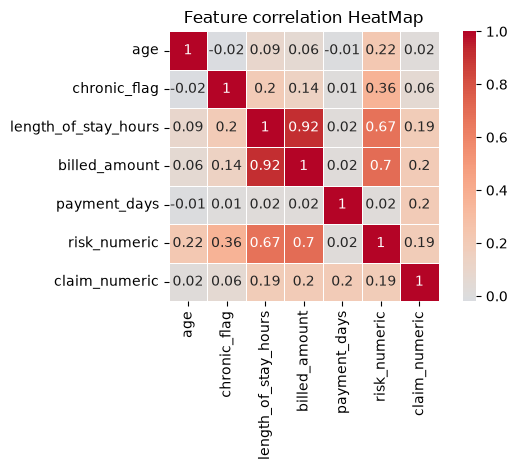

In [26]:
#Full corellation heat map

numeric_cols = [
    "age",
    "chronic_flag",
    "length_of_stay_hours",
    "billed_amount",
    "payment_days",
    "risk_numeric",
    "claim_numeric"
]
corr = df[numeric_cols].corr().round(2)
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, linewidth=0.5, square=True)
plt.title("Feature correlation HeatMap")
plt.tight_layout()
plt.show()

In [27]:
corr_risk = corr["risk_numeric"].drop("risk_numeric")

print("correlation with risk_score sorted:")
print(corr_risk.sort_values(ascending=False).round(3))

correlation with risk_score sorted:
billed_amount           0.70
length_of_stay_hours    0.67
chronic_flag            0.36
age                     0.22
claim_numeric           0.19
payment_days            0.02
Name: risk_numeric, dtype: float64


In [28]:
corr_claim = corr["claim_numeric"].drop("claim_numeric")

print("correlation with claim_status sorted:")
print(corr_claim.sort_values(ascending=False).round(3))

correlation with claim_status sorted:
payment_days            0.20
billed_amount           0.20
length_of_stay_hours    0.19
risk_numeric            0.19
chronic_flag            0.06
age                     0.02
Name: claim_numeric, dtype: float64


In [29]:
df.head()

,patient_id,age,gender,city,insurance_provider,chronic_flag,registration_date,visit_id,visit_date,department,...,risk_score,doctor_id,bill_id,billed_amount,approved_amount,claim_status,payment_days,billing_date,risk_numeric,claim_numeric
0,2,15,F,Mumbai,CareOne,0,2025-12-27,8,2026-01-01,General,...,Low,105,8,9612.77,NaN,Rejected,NaN,2026-01-19,0,2
1,12,3,M,Bangalore,CareOne,0,2025-08-13,65,2026-01-01,ICU,...,High,112,65,88539.01,NaN,Rejected,NaN,2026-01-05,2,2
2,129,44,M,Pune,MediCareX,1,2025-07-20,651,2026-01-01,ICU,...,High,150,651,88539.01,NaN,Pending,NaN,2026-01-20,2,1
3,133,47,F,Delhi,CareOne,1,2025-11-02,670,2026-01-01,General,...,Medium,145,670,20958.52,20322.91,Paid,48.0,2026-01-15,1,0
4,139,14,F,Chennai,SecureLife,1,2025-02-05,706,2026-01-01,Cardiology,...,Medium,148,706,74921.48,72277.09,Paid,27.0,2026-01-16,1,0


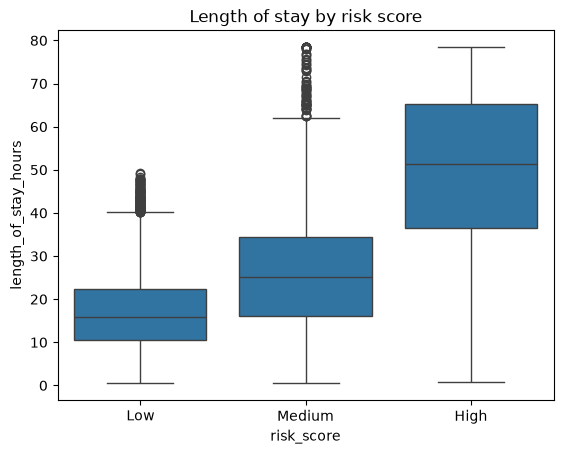


Mean LOS by risk score:
risk_score
High      50.689977
Low       16.919049
Medium    26.097004
Name: length_of_stay_hours, dtype: float64 2


In [30]:
sns.boxplot(data=df, x = "risk_score", y="length_of_stay_hours", order = ["Low", "Medium", "High"])
plt.title("Length of stay by risk score")
plt.show()
print("\nMean LOS by risk score:")
print(df.groupby("risk_score")["length_of_stay_hours"].mean(),round(2))


rejection rate by insurance provider(%)
insurance_provider
CareOne       25.7
MediCareX     24.3
HealthPlus    18.7
SecureLife    15.7
Name: is_rejected, dtype: float64


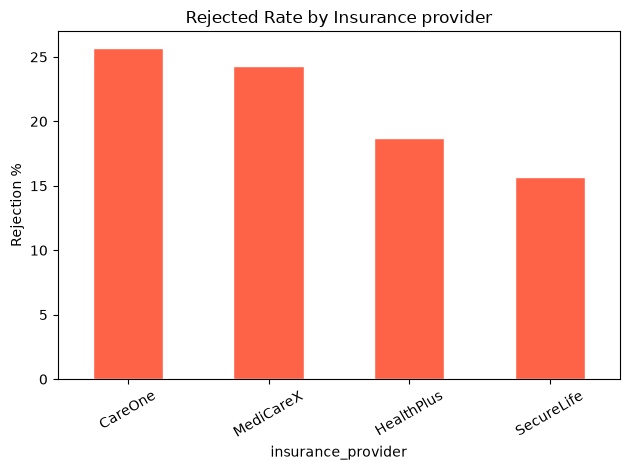

In [31]:
df["is_rejected"] = (df["claim_status"] == "Rejected").astype(int)
rej_rate = (df.groupby("insurance_provider")["is_rejected"]
            .mean()
            .sort_values(ascending=False)
            .mul(100)
            .round(1))
print("rejection rate by insurance provider(%)")

print(rej_rate)

rej_rate.plot(kind="bar", color = "tomato", edgecolor = "white")
plt.title("Rejected Rate by Insurance provider")
plt.ylabel("Rejection %")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [32]:
#class imbalance and deep dive

#naive baseline - what happens if we always predict majority class

most_commom = df["risk_score"].mode()[0]
naive_acc = (df["risk_score"] == most_commom).mean() 
print(f"Majority class: '{most_commom}'")
print(f"Naive Accuracy: '{naive_acc:.1%}'")

Majority class: 'Low'
Naive Accuracy: '46.9%'


In [33]:
#demo setup - two features only
df.head()

,patient_id,age,gender,city,insurance_provider,chronic_flag,registration_date,visit_id,visit_date,department,...,doctor_id,bill_id,billed_amount,approved_amount,claim_status,payment_days,billing_date,risk_numeric,claim_numeric,is_rejected
0,2,15,F,Mumbai,CareOne,0,2025-12-27,8,2026-01-01,General,...,105,8,9612.77,NaN,Rejected,NaN,2026-01-19,0,2,1
1,12,3,M,Bangalore,CareOne,0,2025-08-13,65,2026-01-01,ICU,...,112,65,88539.01,NaN,Rejected,NaN,2026-01-05,2,2,1
2,129,44,M,Pune,MediCareX,1,2025-07-20,651,2026-01-01,ICU,...,150,651,88539.01,NaN,Pending,NaN,2026-01-20,2,1,0
3,133,47,F,Delhi,CareOne,1,2025-11-02,670,2026-01-01,General,...,145,670,20958.52,20322.91,Paid,48.0,2026-01-15,1,0,0
4,139,14,F,Chennai,SecureLife,1,2025-02-05,706,2026-01-01,Cardiology,...,148,706,74921.48,72277.09,Paid,27.0,2026-01-16,1,0,0


In [34]:
X_demo  = df[["length_of_stay_hours", "chronic_flag"]].fillna(0)
y_demo = df["risk_score"]
model_bad = LogisticRegression(max_iter=1000, random_state=42)
model_bad.fit(X_demo, y_demo)
pred_bad = model_bad.predict(X_demo)
print("Without class_weight = 'balanced:'")
print("-"*45)
print(classification_report(y_demo, pred_bad))

Without class_weight = 'balanced:'
---------------------------------------------
              precision    recall  f1-score   support

        High       0.78      0.63      0.69      4316
         Low       0.72      0.78      0.75     11735
      Medium       0.56      0.55      0.56      8949

    accuracy                           0.67     25000
   macro avg       0.69      0.65      0.67     25000
weighted avg       0.67      0.67      0.67     25000



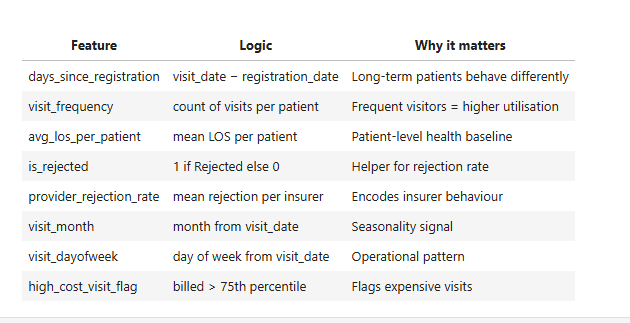

In [35]:
df.head(0)

,patient_id,age,gender,city,insurance_provider,chronic_flag,registration_date,visit_id,visit_date,department,...,doctor_id,bill_id,billed_amount,approved_amount,claim_status,payment_days,billing_date,risk_numeric,claim_numeric,is_rejected


In [36]:
#date of registration

df["days_since_registration"] = abs(df["visit_date"]-df["registration_date"]).dt.days
df[["patient_id", "visit_date", "registration_date", "days_since_registration"]].head()

,patient_id,visit_date,registration_date,days_since_registration
0,2,2026-01-01,2025-12-27,5
1,12,2026-01-01,2025-08-13,141
2,129,2026-01-01,2025-07-20,165
3,133,2026-01-01,2025-11-02,60
4,139,2026-01-01,2025-02-05,330


In [37]:
df.head(2)

,patient_id,age,gender,city,insurance_provider,chronic_flag,registration_date,visit_id,visit_date,department,...,bill_id,billed_amount,approved_amount,claim_status,payment_days,billing_date,risk_numeric,claim_numeric,is_rejected,days_since_registration
0,2,15,F,Mumbai,CareOne,0,2025-12-27,8,2026-01-01,General,...,8,9612.77,NaN,Rejected,NaN,2026-01-19,0,2,1,5
1,12,3,M,Bangalore,CareOne,0,2025-08-13,65,2026-01-01,ICU,...,65,88539.01,NaN,Rejected,NaN,2026-01-05,2,2,1,141


In [38]:
#visit frequency of the patient
df["visit_frequency"] = df.groupby("patient_id")["visit_id"].transform("count")
df[["patient_id", "visit_frequency"]].drop_duplicates().head(10)

,patient_id,visit_frequency
0,2,4
1,12,8
2,129,3
3,133,3
4,139,9
5,170,6
6,216,5
7,222,5
8,243,9
9,335,5


In [39]:
#average LOS per patient
df["avg_LOS_per_patient"] = df.groupby("patient_id")["length_of_stay_hours"].transform("mean")
df[
    ["patient_id", "length_of_stay_hours", "avg_LOS_per_patient"]
].head()

,patient_id,length_of_stay_hours,avg_LOS_per_patient
0,2,9.63,21.120000
1,12,59.60,23.750000
2,129,59.28,32.460000
3,133,25.15,30.056667
4,139,42.88,29.030000


In [40]:
#Provider rejection rate
df["provider_rejection_rate"] = df.groupby("insurance_provider")["is_rejected"].transform("mean")

print("rejection rate per provider:")
# df[["insurance_provider", "provider_rejection_rate"]].head()

df.groupby("insurance_provider")["provider_rejection_rate"].first().round(3)

rejection rate per provider:


insurance_provider
CareOne       0.257
HealthPlus    0.187
MediCareX     0.243
SecureLife    0.157
Name: provider_rejection_rate, dtype: float64

In [41]:
#time based features
df["visit_month"] = df["visit_date"].dt.month
df["visit_dayofweek"] = df["visit_date"].dt.dayofweek
df[["visit_date", "visit_month", "visit_dayofweek"]].head()

,visit_date,visit_month,visit_dayofweek
0,2026-01-01,1,3
1,2026-01-01,1,3
2,2026-01-01,1,3
3,2026-01-01,1,3
4,2026-01-01,1,3


In [42]:
high_cost_threshold = df["billed_amount"].quantile(0.75)
df["high_cost_visit_flag"] = (df["billed_amount"]>high_cost_threshold).astype(int)

print(f"High cost threshold (75th percentile: Rs {high_cost_threshold:,.0f})")
print()
print(df["high_cost_visit_flag"].value_counts())


High cost threshold (75th percentile: Rs 59,711)

high_cost_visit_flag
0    18750
1     6250
Name: count, dtype: int64


In [43]:
#final feature check
new_features = [
    "days_since_registration",
    "visit_frequency",
    "avg_LOS_per_patient",
    "provider_rejection_rate",
    "visit_month",
    "visit_dayofweek",
    "high_cost_visit_flag"
]

print("New features added: ")
for f in new_features:
    print(f"✔️ {f}")


print(f"final dataset shape: {df.shape}")


New features added: 
✔️ days_since_registration
✔️ visit_frequency
✔️ avg_LOS_per_patient
✔️ provider_rejection_rate
✔️ visit_month
✔️ visit_dayofweek
✔️ high_cost_visit_flag
final dataset shape: (25000, 30)


In [44]:
df[new_features].describe().round(3)

,days_since_registration,visit_frequency,avg_LOS_per_patient,provider_rejection_rate,visit_month,visit_dayofweek,high_cost_visit_flag
count,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000
mean,91.661,6.043,26.035,0.211,7.571,2.984,0.250
std,80.651,2.386,8.480,0.040,4.097,2.021,0.433
min,1.000,1.000,0.500,0.157,1.000,0.000,0.000
25%,25.000,4.000,20.061,0.187,4.000,1.000,0.000
50%,69.000,6.000,25.130,0.187,9.000,3.000,0.000
75%,140.000,8.000,30.815,0.257,11.000,5.000,0.250
max,363.000,14.000,78.420,0.257,12.000,6.000,1.000


In [45]:
model_good = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model_good.fit(X_demo, y_demo)
pred_good = model_good.predict(X_demo)
print("with class_weight = balanced: ")
print("-"*45)
print(classification_report(y_demo, pred_good))

with class_weight = balanced: 
---------------------------------------------
              precision    recall  f1-score   support

        High       0.62      0.74      0.67      4316
         Low       0.76      0.71      0.73     11735
      Medium       0.54      0.54      0.54      8949

    accuracy                           0.65     25000
   macro avg       0.64      0.66      0.65     25000
weighted avg       0.66      0.65      0.65     25000



In [46]:
from sklearn.metrics import recall_score

recall_high_no_weight = recall_score(y_demo, pred_bad,
                                     labels=["High"], average=None)[0]
recall_high_balanced = recall_score(y_demo, pred_good,
                                     labels=["High"], average=None)[0]

print("HIGH RISK RECALL — NEW CLINICALLY-DERIVED DATA")
print("-" * 45)
print(f"Without class_weight : {recall_high_no_weight:.0%}")
print(f"With class_weight    : {recall_high_balanced:.0%}")
print()
print("COMPARISON — OLD vs NEW DATASET (with class_weight)")
print("-" * 45)
print(f"Old dataset (random labels)  : ~20%  accuracy 37%")
print(f"New dataset (clinical labels): {recall_high_balanced:.0%}  accuracy 67%")
print()
print("Same model. Same 2 features. Labels fixed.")
print("30 percentage point accuracy jump from data quality alone.")

HIGH RISK RECALL — NEW CLINICALLY-DERIVED DATA
---------------------------------------------
Without class_weight : 63%
With class_weight    : 74%

COMPARISON — OLD vs NEW DATASET (with class_weight)
---------------------------------------------
Old dataset (random labels)  : ~20%  accuracy 37%
New dataset (clinical labels): 74%  accuracy 67%

Same model. Same 2 features. Labels fixed.
30 percentage point accuracy jump from data quality alone.


In [47]:
print(df.shape)

print(df["claim_status"].value_counts())

print(df.groupby("insurance_provider")["is_rejected"].agg(["sum", "count", "mean"]))

(25000, 30)
claim_status
Paid        13638
Pending      6096
Rejected     5266
Name: count, dtype: int64
                     sum  count      mean
insurance_provider                       
CareOne             1625   6326  0.256876
HealthPlus          1215   6499  0.186952
MediCareX           1450   5978  0.242556
SecureLife           976   6197  0.157496


In [48]:
df.to_csv("../outputs/model_table.csv", index=False)
print("Model_table.csv saved ✔️")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nReady for phase 3 modelling")

Model_table.csv saved ✔️
Shape: (25000, 30)
Columns: ['patient_id', 'age', 'gender', 'city', 'insurance_provider', 'chronic_flag', 'registration_date', 'visit_id', 'visit_date', 'department', 'visit_type', 'length_of_stay_hours', 'risk_score', 'doctor_id', 'bill_id', 'billed_amount', 'approved_amount', 'claim_status', 'payment_days', 'billing_date', 'risk_numeric', 'claim_numeric', 'is_rejected', 'days_since_registration', 'visit_frequency', 'avg_LOS_per_patient', 'provider_rejection_rate', 'visit_month', 'visit_dayofweek', 'high_cost_visit_flag']

Ready for phase 3 modelling
